In [3]:
!pip install imbalanced-learn -q

# Importovanje biblioteka
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, cohen_kappa_score,
                             roc_auc_score, roc_curve, matthews_corrcoef)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
import warnings
warnings.filterwarnings('ignore')

# Postavke za grafike
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("="*80)
print("SVM KLASIFIKACIJSKI MODEL - CUSTOMER ATTRITION ANALIZA")
print("="*80)

# Montiranje Google Drive-a
from google.colab import drive
drive.mount('/content/drive')

# Učitavanje dataseta
file_path = '/content/drive/MyDrive/clean_dataset.csv'
df = pd.read_csv(file_path)

print(f"\n✓ Dataset uspješno učitan!")
print(f"✓ Broj redova: {df.shape[0]}")
print(f"✓ Broj kolona: {df.shape[1]}")

SVM KLASIFIKACIJSKI MODEL - CUSTOMER ATTRITION ANALIZA
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✓ Dataset uspješno učitan!
✓ Broj redova: 10127
✓ Broj kolona: 20



2. EKSPLORATIVNA ANALIZA PODATAKA

2.1 STRUKTURA DATASETA
--------------------------------------------------------------------------------
  Attrition_Flag_clean  Customer_Age_clean Gender_clean  \
0    Existing Customer                45.0            M   
1    Existing Customer                49.0            F   
2    Existing Customer                46.0            M   
3    Existing Customer                46.0            F   
4    Existing Customer                46.0            M   

   Dependent_count_clean Education_Level_clean Marital_Status_clean  \
0                    3.0           High School              Married   
1                    5.0              Graduate               Single   
2                    3.0              Graduate              Married   
3                    4.0           High School              Unknown   
4                    3.0            Uneducated              Married   

  Income_Category_clean Card_Category_clean  Months_on_book_clean  \
0        

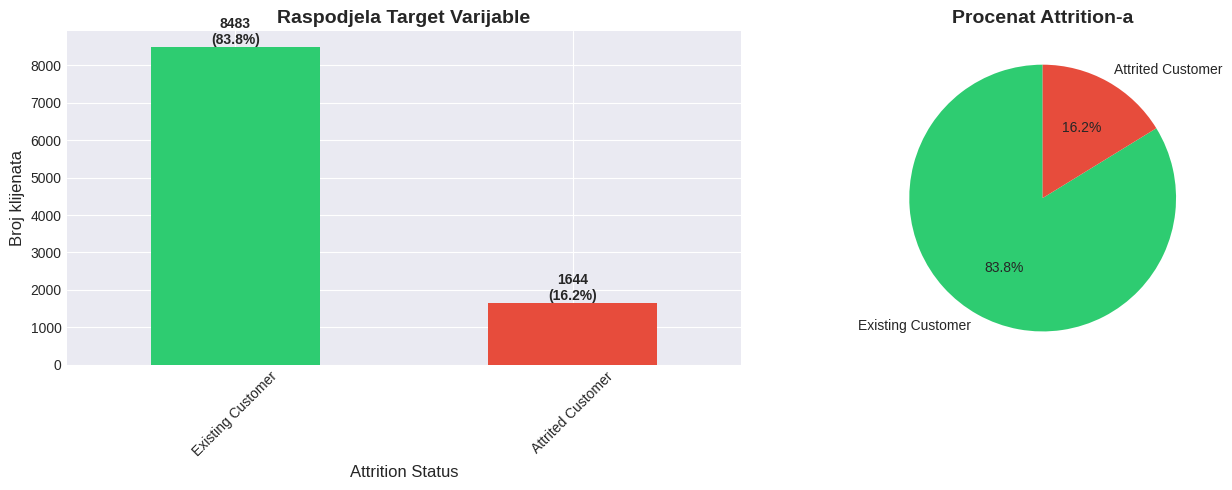


⚠️ ANALIZA BALANSIRANOSTI:
   Omjer manjinske i većinske klase: 0.194
   ⚠️ Dataset je NEBALANSIRAN! (omjer < 0.5)


In [4]:
# ========================================================================
# 2. EKSPLORATIVNA ANALIZA PODATAKA (EDA)
# ========================================================================

print("\n" + "="*80)
print("2. EKSPLORATIVNA ANALIZA PODATAKA")
print("="*80)

# 2.1 Pregled strukture podataka
print("\n2.1 STRUKTURA DATASETA")
print("-"*80)
print(df.head())
print(f"\nDimenzije: {df.shape}")
print(f"\nInfo o kolonama:")
df.info()

# 2.2 Analiza target varijable
print("\n2.2 ANALIZA TARGET VARIJABLE (Attrition_Flag_clean)")
print("-"*80)
target_dist = df['Attrition_Flag_clean'].value_counts()
target_pct = df['Attrition_Flag_clean'].value_counts(normalize=True) * 100

print("\nRaspodela klasa:")
for klasa, count in target_dist.items():
    pct = target_pct[klasa]
    print(f"  {klasa}: {count} ({pct:.2f}%)")

# Vizualizacija raspodele target varijable
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: Bar plot
target_dist.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Raspodjela Target Varijable', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Attrition Status', fontsize=12)
axes[0].set_ylabel('Broj klijenata', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Dodavanje procenata na barove
for i, (klasa, count) in enumerate(target_dist.items()):
    pct = target_pct[klasa]
    axes[0].text(i, count, f'{count}\n({pct:.1f}%)',
                ha='center', va='bottom', fontweight='bold')

# Grafik 2: Pie chart
axes[1].pie(target_dist, labels=target_dist.index, autopct='%1.1f%%',
           colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[1].set_title('Procenat Attrition-a', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Provjera balansiranosti
balance_ratio = target_dist.min() / target_dist.max()
print(f"\n⚠️ ANALIZA BALANSIRANOSTI:")
print(f"   Omjer manjinske i većinske klase: {balance_ratio:.3f}")
if balance_ratio < 0.5:
    print(f"   ⚠️ Dataset je NEBALANSIRAN! (omjer < 0.5)")
else:
    print(f"   ✓ Dataset je relativno balansiran.")


2.3 STATISTIČKA ANALIZA NUMERIČKIH VARIJABLI
--------------------------------------------------------------------------------

Numeričke kolone (14):
['Customer_Age_clean', 'Dependent_count_clean', 'Months_on_book_clean', 'Total_Relationship_Count_clean', 'Months_Inactive_clean', 'Contacts_Count_clean', 'Credit_Limit_clean', 'Total_Revolving_Bal_clean', 'Avg_Open_To_Buy_clean', 'Total_Amt_Chng_clean', 'Total_Trans_Amt_clean', 'Total_Trans_Ct_clean', 'Total_Ct_Chng_clean', 'Avg_Utilization_Ratio_clean']

Statistika:
       Customer_Age_clean  Dependent_count_clean  Months_on_book_clean  \
count        10127.000000           10127.000000          10127.000000   
mean            46.253678               2.252395             35.941641   
std              7.050153               1.171324              7.019558   
min             26.000000               0.000000             13.000000   
25%             43.000000               2.000000             34.000000   
50%             46.000000         

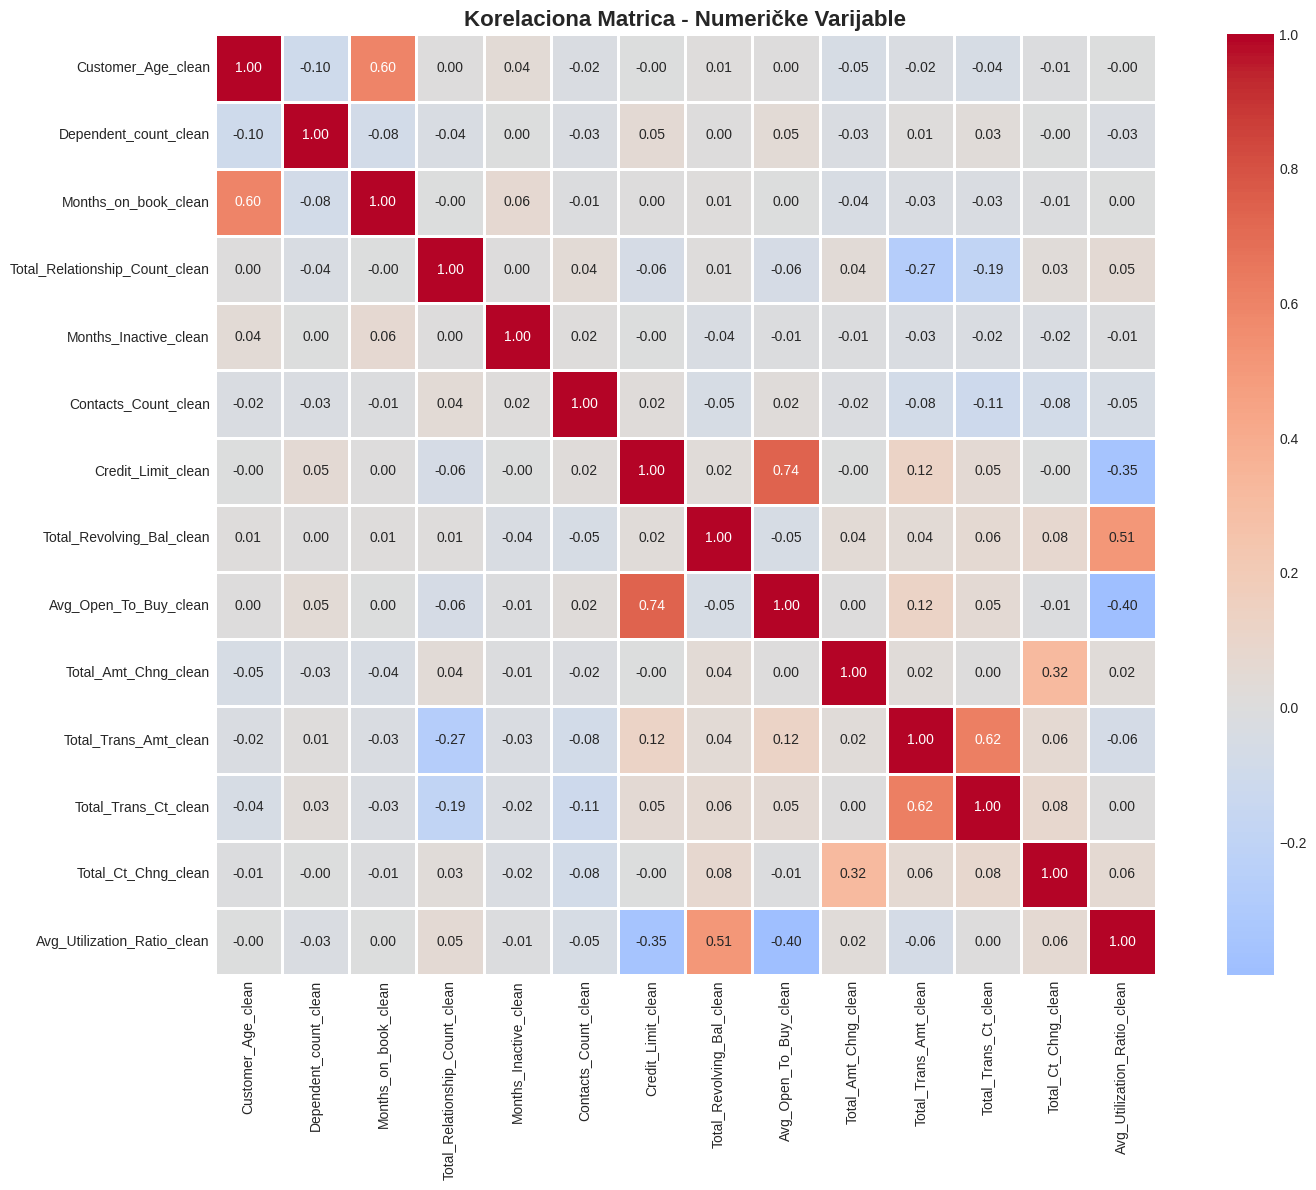


Visoko korelisani parovi (|r| > 0.8):
  ✓ Nema visoko korelisanih parova (multikolinearnost nije problem)


In [5]:
# 2.3 Analiza numeričkih varijabli
print("\n2.3 STATISTIČKA ANALIZA NUMERIČKIH VARIJABLI")
print("-"*80)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumeričke kolone ({len(numeric_cols)}):")
print(numeric_cols)
print("\nStatistika:")
print(df[numeric_cols].describe())

# 2.4 Analiza kategoričkih varijabli
print("\n2.4 ANALIZA KATEGORIČKIH VARIJABLI")
print("-"*80)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"\nKategoričke kolone ({len(categorical_cols)}):")
for col in categorical_cols:
    unique_vals = df[col].nunique()
    print(f"  - {col}: {unique_vals} jedinstvenih vrijednosti")
    print(f"    Vrijednosti: {df[col].unique()[:5]}")  # Prikaži prvih 5

# 2.5 Korelaciona analiza numeričkih varijabli
print("\n2.5 KORELACIONA ANALIZA")
print("-"*80)
plt.figure(figsize=(16, 12))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
           center=0, square=True, linewidths=1)
plt.title('Korelaciona Matrica - Numeričke Varijable', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Identifikacija visoko korelisanih parova
print("\nVisoko korelisani parovi (|r| > 0.8):")
high_corr = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.8:
            high_corr.append((correlation_matrix.columns[i],
                            correlation_matrix.columns[j],
                            correlation_matrix.iloc[i, j]))
            print(f"  {correlation_matrix.columns[i]} <-> {correlation_matrix.columns[j]}: {correlation_matrix.iloc[i, j]:.3f}")

if not high_corr:
    print("  ✓ Nema visoko korelisanih parova (multikolinearnost nije problem)")

In [6]:
# ========================================================================
# 3. PRIPREMA PODATAKA ZA SVM
# ========================================================================
print("\n" + "="*80)
print("3. PRIPREMA PODATAKA ZA SVM ALGORITAM")
print("="*80)

print("""
SPECIFIČNOSTI SVM ALGORITMA:
1. SVM je VEOMA OSJETLJIV na skalu podataka
   → Potrebno je OBAVEZNO skaliranje svih numeričkih varijabli!

2. SVM radi sa numeričkim podacima
   → Kategoričke varijable moraju biti enkodirane

3. SVM može biti računski zahtevan
   → Za velike datasete razmotrite korištenje LinearSVC

4. SVM najbolje radi sa balansiranim podacima
   → Primijenićemo tehnike resamplinga ako je potrebno
""")

# 3.1 Kreiranje kopije dataseta
df_processed = df.copy()

# 3.2 Separacija feature-a i target-a
print("\n3.1 SEPARACIJA FEATURES I TARGET VARIJABLE")
print("-"*80)
X = df_processed.drop('Attrition_Flag_clean', axis=1)
y = df_processed['Attrition_Flag_clean']

print(f"✓ Features (X): {X.shape}")
print(f"✓ Target (y): {y.shape}")
print(f"✓ Target klase: {y.unique()}")

# 3.3 Enkodiranje target varijable
print("\n3.2 ENKODIRANJE TARGET VARIJABLE")
print("-"*80)
le_target = LabelEncoder()
y_encoded = le_target.fit_transform(y)

print("Mapiranje klasa:")
for i, klasa in enumerate(le_target.classes_):
    count = np.sum(y_encoded == i)
    print(f"  {klasa} → {i} (n={count})")

# 3.4 Identifikacija kategoričkih i numeričkih kolona
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numerical_features = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"\n✓ Numeričke kolone: {len(numerical_features)}")
print(f"✓ Kategoričke kolone: {len(categorical_features)}")

# 3.5 Enkodiranje kategoričkih varijabli
print("\n3.3 ENKODIRANJE KATEGORIČKIH VARIJABLI")
print("-"*80)
X_encoded = X.copy()

label_encoders = {}
for col in categorical_features:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X[col])
    label_encoders[col] = le
    print(f"✓ {col}: {X[col].nunique()} kategorije → {le.classes_}")

print(f"\n✓ Svi features su sada numerički!")
print(f"✓ Ukupan broj features: {X_encoded.shape[1]}")

# 3.6 Provjera outliera pomoću IQR metode
print("\n3.4 DETEKCIJA OUTLIERA (IQR METODA)")
print("-"*80)
outlier_summary = []
for col in numerical_features:
    Q1 = X_encoded[col].quantile(0.25)
    Q3 = X_encoded[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((X_encoded[col] < lower_bound) | (X_encoded[col] > upper_bound)).sum()
    outlier_pct = (outliers / len(X_encoded)) * 100

    if outliers > 0:
        outlier_summary.append({
            'Feature': col,
            'Outliers': outliers,
            'Percentage': outlier_pct,
            'Lower': lower_bound,
            'Upper': upper_bound
        })

if outlier_summary:
    outlier_df = pd.DataFrame(outlier_summary)
    print(outlier_df.to_string(index=False))
    print(f"\n⚠️ Detektovano outliera u {len(outlier_summary)} varijabli")
    print("   Napomena: Za SVM, outlieri mogu uticati na performanse.")
    print("   Opcije: Cap outliere, ukloniti ih, ili koristiti robust scaling")
else:
    print("✓ Nema značajnih outliera u datasetu")


3. PRIPREMA PODATAKA ZA SVM ALGORITAM

SPECIFIČNOSTI SVM ALGORITMA:
1. SVM je VEOMA OSJETLJIV na skalu podataka
   → Potrebno je OBAVEZNO skaliranje svih numeričkih varijabli!

2. SVM radi sa numeričkim podacima
   → Kategoričke varijable moraju biti enkodirane

3. SVM može biti računski zahtevan
   → Za velike datasete razmotrite korištenje LinearSVC

4. SVM najbolje radi sa balansiranim podacima
   → Primijenićemo tehnike resamplinga ako je potrebno


3.1 SEPARACIJA FEATURES I TARGET VARIJABLE
--------------------------------------------------------------------------------
✓ Features (X): (10127, 19)
✓ Target (y): (10127,)
✓ Target klase: ['Existing Customer' 'Attrited Customer']

3.2 ENKODIRANJE TARGET VARIJABLE
--------------------------------------------------------------------------------
Mapiranje klasa:
  Attrited Customer → 0 (n=1644)
  Existing Customer → 1 (n=8483)

✓ Numeričke kolone: 14
✓ Kategoričke kolone: 5

3.3 ENKODIRANJE KATEGORIČKIH VARIJABLI
----------------------

In [7]:
# ========================================================================
# 4. PODJELA PODATAKA (Train/Validation/Test)
# ========================================================================

print("\n" + "="*80)
print("4. PODJELA PODATAKA NA TRAIN/VALIDATION/TEST SETOVE")
print("="*80)

print("""
STRATEGIJA PODJELE:
- Train set: 60% (za obučavanje modela)
- Validation set: 20% (za tuning hiperparametara)
- Test set: 20% (za finalnu evaluaciju)

Koristimo stratified split da održimo raspodelu klasa!
""")

# 4.1 Prva podjela: Train+Val vs Test (80% vs 20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_encoded, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# 4.2 Druga podjela: Train vs Validation (75% od temp = 60% ukupno)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,  # 0.25 * 0.8 = 0.2 od ukupnog
    random_state=42,
    stratify=y_temp
)

print("\n4.1 REZULTATI PODJELE")
print("-"*80)
print(f"Train set:      {X_train.shape[0]} uzoraka ({X_train.shape[0]/len(X_encoded)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]} uzoraka ({X_val.shape[0]/len(X_encoded)*100:.1f}%)")
print(f"Test set:       {X_test.shape[0]} uzoraka ({X_test.shape[0]/len(X_encoded)*100:.1f}%)")
print(f"Ukupno:         {len(X_encoded)} uzoraka")

# Provjera stratifikacije
print("\n4.2 PROVJERA STRATIFIKACIJE (Raspodela klasa)")
print("-"*80)
sets_data = {
    'Train': y_train,
    'Validation': y_val,
    'Test': y_test,
    'Original': y_encoded
}

for name, y_set in sets_data.items():
    unique, counts = np.unique(y_set, return_counts=True)
    pct = counts / len(y_set) * 100
    print(f"{name:12} - Klasa 0: {counts[0]:4d} ({pct[0]:.1f}%)  |  Klasa 1: {counts[1]:4d} ({pct[1]:.1f}%)")

print("\n✓ Stratifikacija je uspješno očuvana u svim setovima!")

# 4.3 Skaliranje podataka - KRITIČNO ZA SVM!
print("\n4.3 SKALIRANJE PODATAKA (StandardScaler)")
print("-"*80)
print("""
⚠️ VAŽNO: SVM algoritam je IZUZETNO osjetljiv na skalu podataka!

StandardScaler transformacija: z = (x - μ) / σ
- Centrira podatke (srednja vrijednost = 0)
- Skalira na jediničnu varijansu (std = 1)

Fitujemo scaler SAMO na train setu da izbjegnemo data leakage!
""")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("✓ Skaliranje završeno!")
print(f"\nProvjera - Srednje vrijednosti nakon skaliranja (Train set):")
print(f"  Mean ≈ {X_train_scaled.mean():.6f} (treba biti ≈ 0)")
print(f"  Std  ≈ {X_train_scaled.std():.6f} (treba biti ≈ 1)")


4. PODJELA PODATAKA NA TRAIN/VALIDATION/TEST SETOVE

STRATEGIJA PODJELE:
- Train set: 60% (za obučavanje modela)
- Validation set: 20% (za tuning hiperparametara)
- Test set: 20% (za finalnu evaluaciju)

Koristimo stratified split da održimo raspodelu klasa!


4.1 REZULTATI PODJELE
--------------------------------------------------------------------------------
Train set:      6075 uzoraka (60.0%)
Validation set: 2026 uzoraka (20.0%)
Test set:       2026 uzoraka (20.0%)
Ukupno:         10127 uzoraka

4.2 PROVJERA STRATIFIKACIJE (Raspodela klasa)
--------------------------------------------------------------------------------
Train        - Klasa 0:  986 (16.2%)  |  Klasa 1: 5089 (83.8%)
Validation   - Klasa 0:  329 (16.2%)  |  Klasa 1: 1697 (83.8%)
Test         - Klasa 0:  329 (16.2%)  |  Klasa 1: 1697 (83.8%)
Original     - Klasa 0: 1644 (16.2%)  |  Klasa 1: 8483 (83.8%)

✓ Stratifikacija je uspješno očuvana u svim setovima!

4.3 SKALIRANJE PODATAKA (StandardScaler)
-----------------

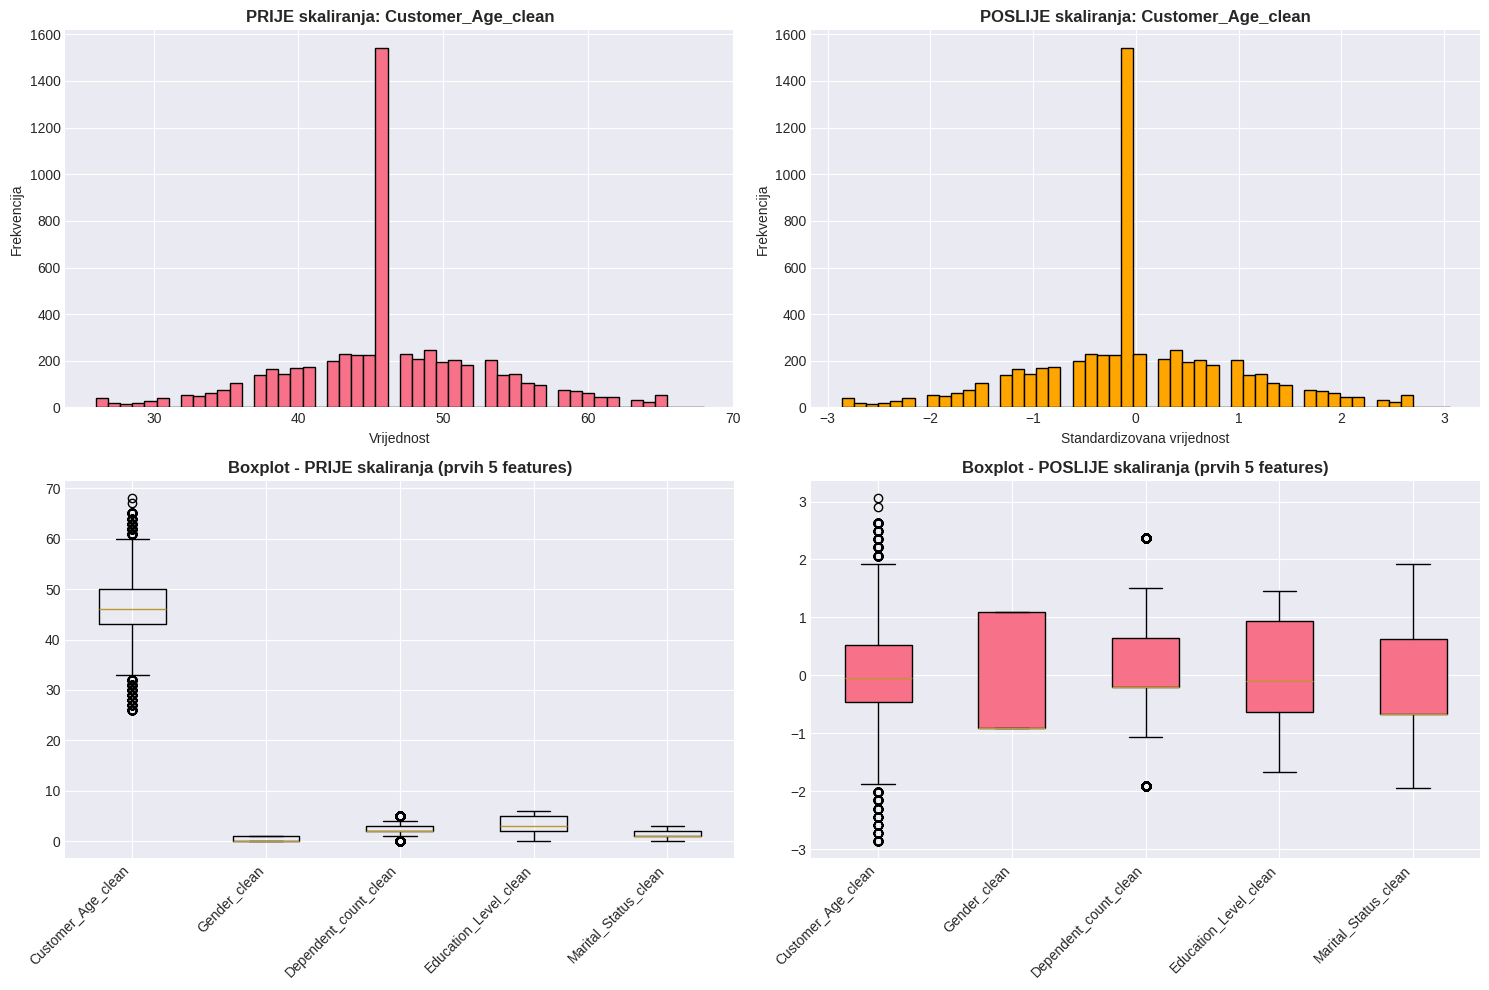

In [8]:
# Vizualizacija prije i poslije skaliranja
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Primjer prije skaliranja
sample_feature = X_train.iloc[:, 0]
axes[0, 0].hist(sample_feature, bins=50, edgecolor='black')
axes[0, 0].set_title(f'PRIJE skaliranja: {X_train.columns[0]}', fontweight='bold')
axes[0, 0].set_xlabel('Vrijednost')
axes[0, 0].set_ylabel('Frekvencija')

# Nakon skaliranja
axes[0, 1].hist(X_train_scaled[:, 0], bins=50, edgecolor='black', color='orange')
axes[0, 1].set_title(f'POSLIJE skaliranja: {X_train.columns[0]}', fontweight='bold')
axes[0, 1].set_xlabel('Standardizovana vrijednost')
axes[0, 1].set_ylabel('Frekvencija')

# Boxplot prije
sample_features_before = X_train.iloc[:, :5]
axes[1, 0].boxplot([sample_features_before.iloc[:, i] for i in range(5)])
axes[1, 0].set_title('Boxplot - PRIJE skaliranja (prvih 5 features)', fontweight='bold')
axes[1, 0].set_xticklabels(sample_features_before.columns, rotation=45, ha='right')

# Boxplot poslije
axes[1, 1].boxplot([X_train_scaled[:, i] for i in range(5)], patch_artist=True)
axes[1, 1].set_title('Boxplot - POSLIJE skaliranja (prvih 5 features)', fontweight='bold')
axes[1, 1].set_xticklabels(sample_features_before.columns, rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [9]:
# ========================================================================
# 5. IZGRADNJA BAZNOG SVM MODELA
# ========================================================================

print("\n" + "="*80)
print("5. IZGRADNJA BAZNOG SVM MODELA")
print("="*80)

print("""
TEORIJSKA OSNOVA SVM-a:
-----------------------
Support Vector Machine (SVM) je moćan algoritam za klasifikaciju koji:
1. Pronalazi optimalnu hiperravnu koja razdvaja klase
2. Maksimizuje marginu između klasa
3. Koristi kernel funkcije za nelinearne probleme

OSNOVNI HIPERPARAMETRI:
- C: regularizacioni parametar (trade-off između margine i grešaka)
- kernel: tip kernela ('linear', 'rbf', 'poly', 'sigmoid')
- gamma: parametar za rbf, poly i sigmoid kernele

Za početak koristimo default parametre (C=1.0, kernel='rbf', gamma='scale')
""")

# 5.1 Kreiranje baznog modela
print("\n5.1 KREIRANJE I TRENIRANJE BAZNOG MODELA")
print("-"*80)
print("Parametri:")
print("  - C = 1.0")
print("  - kernel = 'rbf' (Radial Basis Function)")
print("  - gamma = 'scale'")
print("  - random_state = 42")

svm_baseline = SVC(
    C=1.0,
    kernel='rbf',
    gamma='scale',
    random_state=42,
    probability=True  # Omogućava predict_proba() za ROC AUC
)

# Treniranje modela
print("\n⏳ Treniranje modela u toku...")
svm_baseline.fit(X_train_scaled, y_train)
print("✓ Model uspješno istreniran!")

# 5.2 Informacije o modelu
print("\n5.2 INFORMACIJE O MODELU")
print("-"*80)
print(f"Broj support vektora: {svm_baseline.n_support_}")
print(f"  - Klasa 0: {svm_baseline.n_support_[0]} support vektora")
print(f"  - Klasa 1: {svm_baseline.n_support_[1]} support vektora")
print(f"Ukupno support vektora: {sum(svm_baseline.n_support_)}")
print(f"Procenat support vektora: {sum(svm_baseline.n_support_)/len(X_train_scaled)*100:.2f}%")



5. IZGRADNJA BAZNOG SVM MODELA

TEORIJSKA OSNOVA SVM-a:
-----------------------
Support Vector Machine (SVM) je moćan algoritam za klasifikaciju koji:
1. Pronalazi optimalnu hiperravnu koja razdvaja klase
2. Maksimizuje marginu između klasa
3. Koristi kernel funkcije za nelinearne probleme

OSNOVNI HIPERPARAMETRI:
- C: regularizacioni parametar (trade-off između margine i grešaka)
- kernel: tip kernela ('linear', 'rbf', 'poly', 'sigmoid')
- gamma: parametar za rbf, poly i sigmoid kernele

Za početak koristimo default parametre (C=1.0, kernel='rbf', gamma='scale')


5.1 KREIRANJE I TRENIRANJE BAZNOG MODELA
--------------------------------------------------------------------------------
Parametri:
  - C = 1.0
  - kernel = 'rbf' (Radial Basis Function)
  - gamma = 'scale'
  - random_state = 42

⏳ Treniranje modela u toku...
✓ Model uspješno istreniran!

5.2 INFORMACIJE O MODELU
--------------------------------------------------------------------------------
Broj support vektora: [ 793 10

In [10]:
# ========================================================================
# 6. EVALUACIJA MODELA - Konfuzijska matrica i metrike
# ========================================================================

print("\n" + "="*80)
print("6. EVALUACIJA BAZNOG MODELA")
print("="*80)

# 6.1 Predikcije na svim setovima
y_train_pred = svm_baseline.predict(X_train_scaled)
y_val_pred = svm_baseline.predict(X_val_scaled)
y_test_pred = svm_baseline.predict(X_test_scaled)

# 6.2 Funkcija za detaljnu evaluaciju
def evaluate_model(y_true, y_pred, y_proba, set_name=""):
    """Detaljna evaluacija klasifikacijskog modela"""

    print(f"\n{'='*80}")
    print(f"EVALUACIJA - {set_name}")
    print(f"{'='*80}")

    # Konfuzijska matrica
    cm = confusion_matrix(y_true, y_pred)

    # Osnovne metrike
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    # Dodatne metrike
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)

    # Specifičnost i osjetljivost po klasama
    tn, fp, fn, tp = cm.ravel()
    sensitivity_class1 = tp / (tp + fn) if (tp + fn) > 0 else 0  # Recall za klasu 1
    specificity_class0 = tn / (tn + fp) if (tn + fp) > 0 else 0  # Specifičnost za klasu 0

    # ROC AUC
    try:
        roc_auc = roc_auc_score(y_true, y_proba[:, 1])
    except:
        roc_auc = None

    # Ispis metrika
    print(f"\n📊 OSNOVNE METRIKE:")
    print(f"{'─'*80}")
    print(f"  Tačnost (Accuracy):        {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"  Preciznost (Precision):    {precision:.4f}")
    print(f"  Odziv (Recall/Sensitivity):{recall:.4f}")
    print(f"  F1 Score:                  {f1:.4f}")

    print(f"\n📊 DODATNE METRIKE:")
    print(f"{'─'*80}")
    print(f"  Cohen's Kappa:             {kappa:.4f}")
    print(f"  Matthews Correlation:      {mcc:.4f}")
    print(f"  Specifičnost (Klasa 0):    {specificity_class0:.4f}")
    print(f"  Osjetljivost (Klasa 1):    {sensitivity_class1:.4f}")
    if roc_auc:
        print(f"  ROC AUC Score:             {roc_auc:.4f}")

    # Interpretacija Cohen's Kappa
    print(f"\n📝 INTERPRETACIJA COHEN'S KAPPA ({kappa:.4f}):")
    if kappa < 0:
        interpretation = "Nema slaganja (lošije od slučajnog)"
    elif kappa < 0.20:
        interpretation = "Slabo slaganje"
    elif kappa < 0.40:
        interpretation = "Umjereno slaganje"
    elif kappa < 0.60:
        interpretation = "Značajno slaganje"
    elif kappa < 0.80:
        interpretation = "Jako slaganje"
    else:
        interpretation = "Gotovo savršeno slaganje"
    print(f"  → {interpretation}")

    print(f"\n📊 KONFUZIJSKA MATRICA:")
    print(f"{'─'*80}")
    print(f"\n                    Predviđena Klasa")
    print(f"                    ┌─────────┬─────────┐")
    print(f"                    │ Klasa 0 │ Klasa 1 │")
    print(f"  ┌────────────────┼─────────┼─────────┤")
    print(f"  │ Stvarna        │         │         │")
    print(f"  │ Klasa 0        │  {tn:5d}  │  {fp:5d}  │  TN / FP")
    print(f"  │                │         │         │")
    print(f"  ├────────────────┼─────────┼─────────┤")
    print(f"  │ Stvarna        │         │         │")
    print(f"  │ Klasa 1        │  {fn:5d}  │  {tp:5d}  │  FN / TP")
    print(f"  │                │         │         │")
    print(f"  └────────────────┴─────────┴─────────┘")

    print(f"\n  TN (True Negative):  {tn:5d} - Ispravno predviđena klasa 0")
    print(f"  FP (False Positive): {fp:5d} - Pogrešno predviđena klasa 1 (Type I error)")
    print(f"  FN (False Negative): {fn:5d} - Pogrešno predviđena klasa 0 (Type II error)")
    print(f"  TP (True Positive):  {tp:5d} - Ispravno predviđena klasa 1")

    # Classification report
    print(f"\n📊 CLASSIFICATION REPORT:")
    print(f"{'─'*80}")
    print(classification_report(y_true, y_pred, target_names=['Klasa 0', 'Klasa 1']))

    return cm, accuracy, kappa, roc_auc


6. EVALUACIJA BAZNOG MODELA



EVALUACIJA - TRAIN SET

📊 OSNOVNE METRIKE:
────────────────────────────────────────────────────────────────────────────────
  Tačnost (Accuracy):        0.9172 (91.72%)
  Preciznost (Precision):    0.9158
  Odziv (Recall/Sensitivity):0.9172
  F1 Score:                  0.9089

📊 DODATNE METRIKE:
────────────────────────────────────────────────────────────────────────────────
  Cohen's Kappa:             0.6400
  Matthews Correlation:      0.6647
  Specifičnost (Klasa 0):    0.5538
  Osjetljivost (Klasa 1):    0.9876
  ROC AUC Score:             0.9481

📝 INTERPRETACIJA COHEN'S KAPPA (0.6400):
  → Jako slaganje

📊 KONFUZIJSKA MATRICA:
────────────────────────────────────────────────────────────────────────────────

                    Predviđena Klasa
                    ┌─────────┬─────────┐
                    │ Klasa 0 │ Klasa 1 │
  ┌────────────────┼─────────┼─────────┤
  │ Stvarna        │         │         │
  │ Klasa 0        │    546  │    440  │  TN / FP
  │                │  

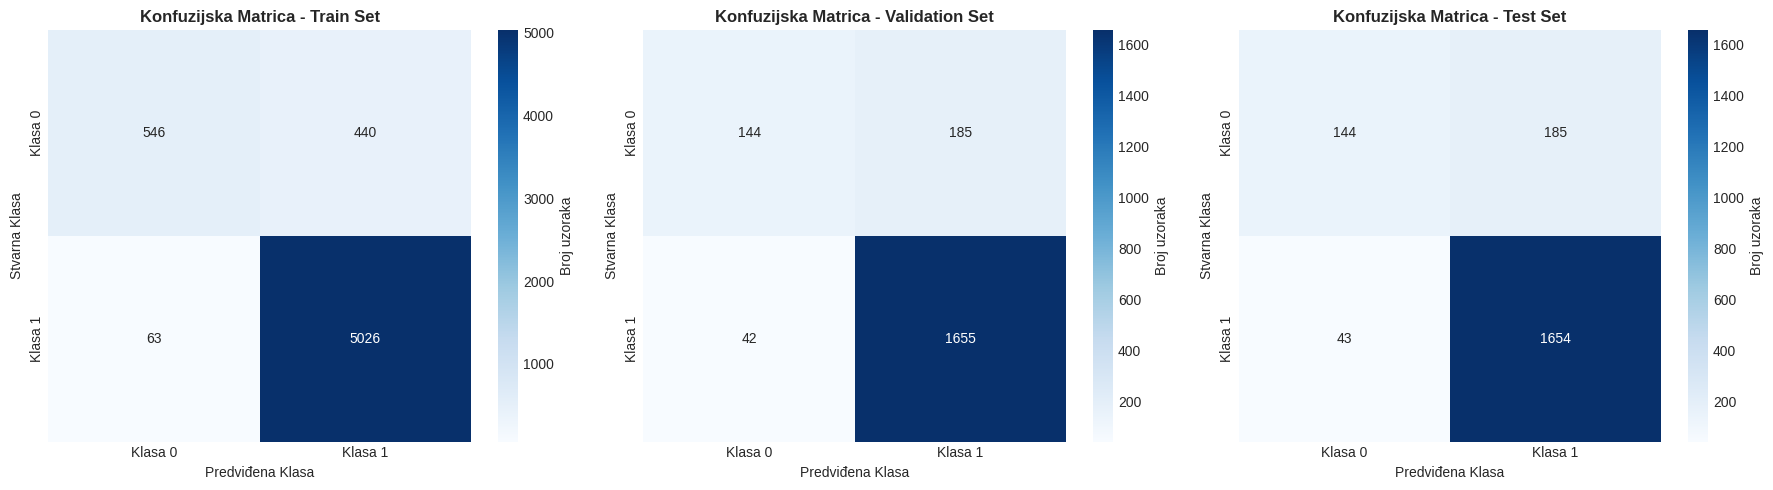

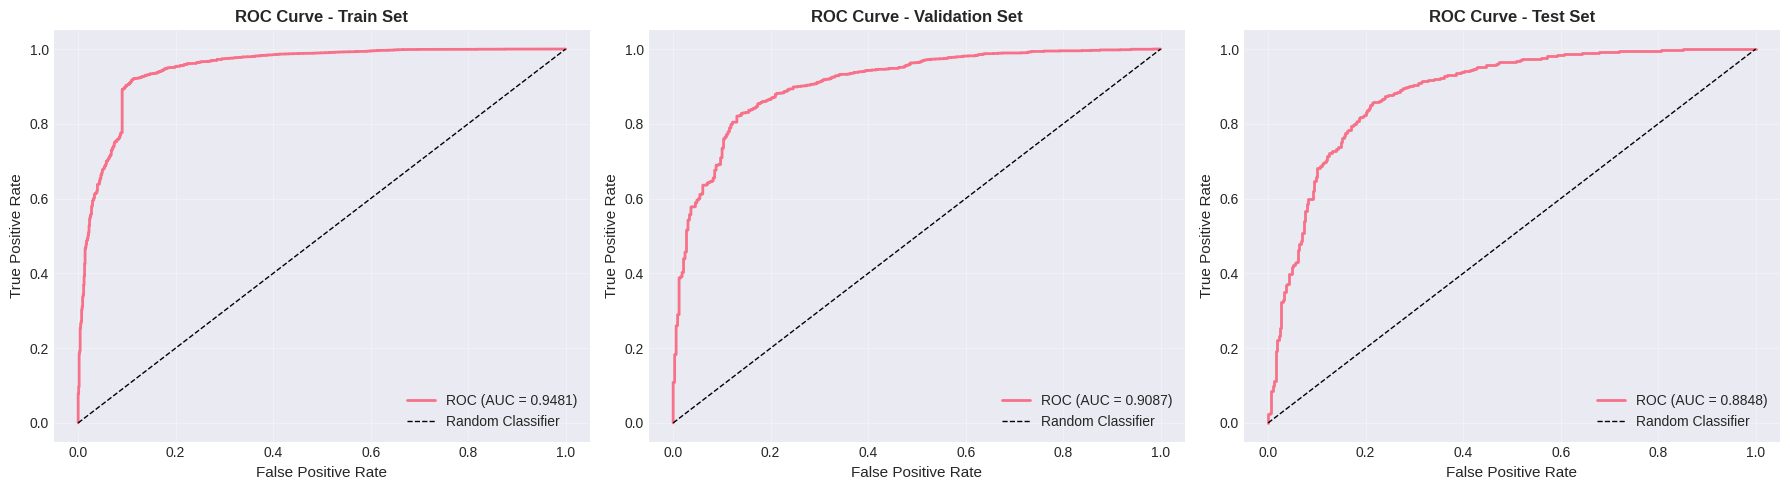


✓ Bazna evaluacija završena!


In [11]:
# 6.3 Evaluacija na svim setovima
y_train_proba = svm_baseline.predict_proba(X_train_scaled)
y_val_proba = svm_baseline.predict_proba(X_val_scaled)
y_test_proba = svm_baseline.predict_proba(X_test_scaled)

cm_train, acc_train, kappa_train, auc_train = evaluate_model(
    y_train, y_train_pred, y_train_proba, "TRAIN SET"
)

cm_val, acc_val, kappa_val, auc_val = evaluate_model(
    y_val, y_val_pred, y_val_proba, "VALIDATION SET"
)

cm_test, acc_test, kappa_test, auc_test = evaluate_model(
    y_test, y_test_pred, y_test_proba, "TEST SET"
)

# 6.4 Komparacija performansi
print("\n" + "="*80)
print("6.4 KOMPARACIJA PERFORMANSI IZMEĐU SETOVA")
print("="*80)

comparison = pd.DataFrame({
    'Train': [acc_train, kappa_train, auc_train],
    'Validation': [acc_val, kappa_val, auc_val],
    'Test': [acc_test, kappa_test, auc_test]
}, index=['Accuracy', 'Cohen Kappa', 'ROC AUC'])

print("\n", comparison.round(4))

# Provjera overfittinga
print(f"\n📊 ANALIZA OVERFITTING-a:")
print("-"*80)
acc_diff = acc_train - acc_test
if acc_diff > 0.05:
    print(f"⚠️ UPOZORENJE: Razlika u accuracy Train vs Test: {acc_diff:.4f}")
    print("   Model pokazuje znakove overfittinga!")
elif acc_diff > 0.02:
    print(f"⚠️ Blagi overfit: {acc_diff:.4f} razlike između Train i Test seta")
else:
    print(f"✓ Model je dobro generalizovan (razlika: {acc_diff:.4f})")

# Vizualizacija konfuzijskih matrica
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (cm, title) in enumerate([(cm_train, 'Train'), (cm_val, 'Validation'), (cm_test, 'Test')]):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
               cbar_kws={'label': 'Broj uzoraka'})
    axes[idx].set_title(f'Konfuzijska Matrica - {title} Set', fontweight='bold', fontsize=12)
    axes[idx].set_ylabel('Stvarna Klasa')
    axes[idx].set_xlabel('Predviđena Klasa')
    axes[idx].set_xticklabels(['Klasa 0', 'Klasa 1'])
    axes[idx].set_yticklabels(['Klasa 0', 'Klasa 1'])

plt.tight_layout()
plt.show()

# 6.5 ROC Curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (y_true, y_proba, title) in enumerate([
    (y_train, y_train_proba, 'Train'),
    (y_val, y_val_proba, 'Validation'),
    (y_test, y_test_proba, 'Test')
]):
    fpr, tpr, thresholds = roc_curve(y_true, y_proba[:, 1])
    auc_score = roc_auc_score(y_true, y_proba[:, 1])

    axes[idx].plot(fpr, tpr, linewidth=2, label=f'ROC (AUC = {auc_score:.4f})')
    axes[idx].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
    axes[idx].set_xlabel('False Positive Rate', fontsize=11)
    axes[idx].set_ylabel('True Positive Rate', fontsize=11)
    axes[idx].set_title(f'ROC Curve - {title} Set', fontweight='bold', fontsize=12)
    axes[idx].legend(loc='lower right')
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Bazna evaluacija završena!")

In [12]:
# ========================================================================
# 7. UNAKRSNA VALIDACIJA
# ========================================================================

print("\n" + "="*80)
print("7. UNAKRSNA VALIDACIJA (CROSS-VALIDATION)")
print("="*80)

print("""
UNAKRSNA VALIDACIJA - Teorija i Primjena
-----------------------------------------
Unakrsna validacija (Cross-Validation) je tehnika za robusnu evaluaciju modela.

STRATIFIED K-FOLD (k=5):
- Dijeli podatke na 5 dijelova (foldova)
- Svaki fold čuva originalnu raspodelu klasa (stratified)
- Model se trenira 5 puta, svaki put na različitih 80% podataka
- Testira se na preostalih 20% koji nisu viđeni
- Finalna metrika = prosjek svih 5 evaluacija

PREDNOSTI:
✓ Više pouzdana procjena performansi od jedne podjele
✓ Svi podaci se koriste i za trening i za testiranje
✓ Smanjuje uticaj slučajne podjele podataka
✓ Bolje detektuje overfitting
""")

# 7.1 Priprema za unakrsnu validaciju
# Kombinujemo train i validation set za CV
X_train_val_scaled = np.vstack([X_train_scaled, X_val_scaled])
y_train_val = np.concatenate([y_train, y_val])

print(f"\n7.1 PRIPREMA PODATAKA ZA CV")
print("-"*80)
print(f"Kombinirani Train+Val set: {X_train_val_scaled.shape[0]} uzoraka")
print(f"Broj foldova: 5")
print(f"Stratified: Da (očuvana raspodela klasa)")

# 7.2 Stratified K-Fold Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"\n⏳ Izvršavanje 5-fold cross-validation...")
print(f"   (Ovo može potrajati nekoliko minuta...)\n")

cv_scores = {}
cv_metrics = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'roc_auc']

for metric in cv_metrics:
    print(f"  Računam {metric}...", end='')
    scores = cross_val_score(
        svm_baseline,
        X_train_val_scaled,
        y_train_val,
        cv=skf,
        scoring=metric,
        n_jobs=-1  # Koristi sve dostupne procesore
    )
    cv_scores[metric] = scores
    print(f" ✓ Završeno")

print("\n7.2 REZULTATI UNAKRSNE VALIDACIJE")
print("="*80)

cv_results = []
for metric, scores in cv_scores.items():
    cv_results.append({
        'Metrika': metric,
        'Fold 1': scores[0],
        'Fold 2': scores[1],
        'Fold 3': scores[2],
        'Fold 4': scores[3],
        'Fold 5': scores[4],
        'Mean': scores.mean(),
        'Std': scores.std()
    })

cv_df = pd.DataFrame(cv_results)
print("\n", cv_df.to_string(index=False))


7. UNAKRSNA VALIDACIJA (CROSS-VALIDATION)

UNAKRSNA VALIDACIJA - Teorija i Primjena
-----------------------------------------
Unakrsna validacija (Cross-Validation) je tehnika za robusnu evaluaciju modela.

STRATIFIED K-FOLD (k=5):
- Dijeli podatke na 5 dijelova (foldova)
- Svaki fold čuva originalnu raspodelu klasa (stratified)
- Model se trenira 5 puta, svaki put na različitih 80% podataka
- Testira se na preostalih 20% koji nisu viđeni
- Finalna metrika = prosjek svih 5 evaluacija

PREDNOSTI:
✓ Više pouzdana procjena performansi od jedne podjele
✓ Svi podaci se koriste i za trening i za testiranje
✓ Smanjuje uticaj slučajne podjele podataka
✓ Bolje detektuje overfitting


7.1 PRIPREMA PODATAKA ZA CV
--------------------------------------------------------------------------------
Kombinirani Train+Val set: 8101 uzoraka
Broj foldova: 5
Stratified: Da (očuvana raspodela klasa)

⏳ Izvršavanje 5-fold cross-validation...
   (Ovo može potrajati nekoliko minuta...)

  Računam accuracy... ✓

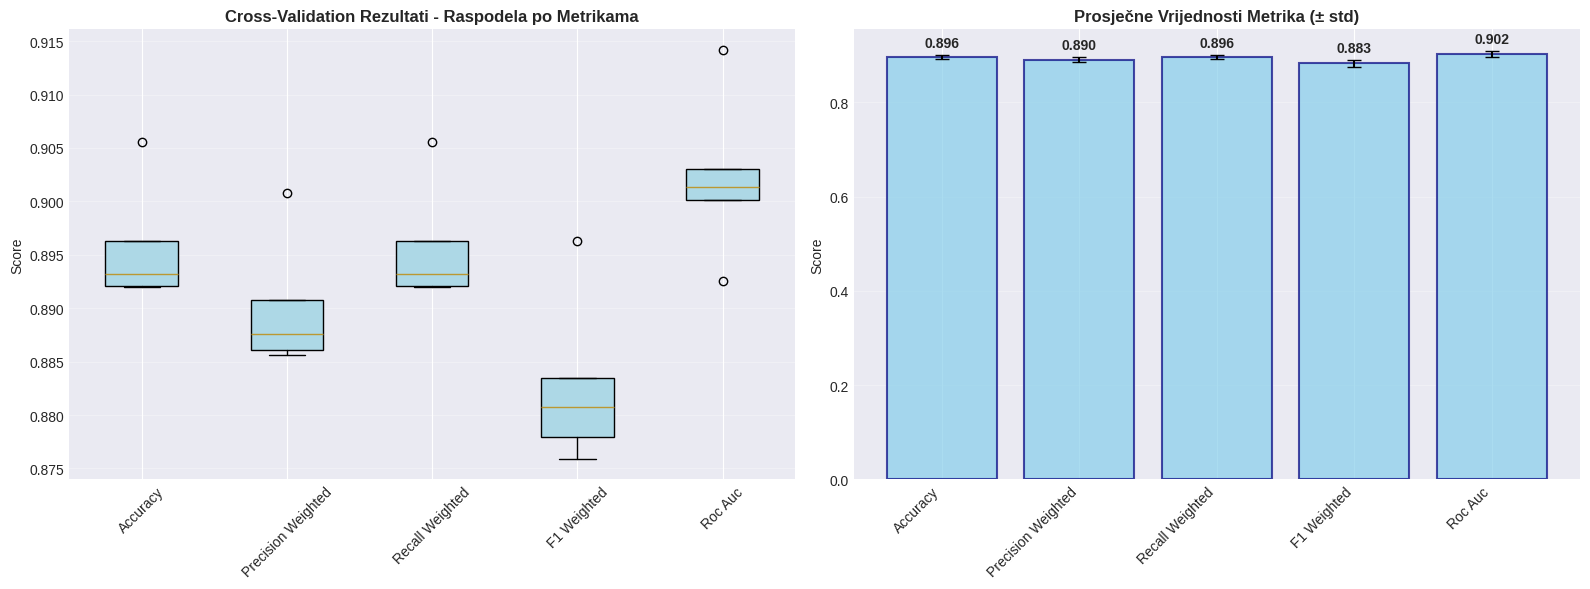


7.3 ANALIZA KONZISTENTNOSTI MODELA

accuracy                  - Mean: 0.8958, Std: 0.0051
                            Coefficient of Variation: 0.57%
                            ✓ Veoma konzistentan model

precision_weighted        - Mean: 0.8902, Std: 0.0056
                            Coefficient of Variation: 0.63%
                            ✓ Veoma konzistentan model

recall_weighted           - Mean: 0.8958, Std: 0.0051
                            Coefficient of Variation: 0.57%
                            ✓ Veoma konzistentan model

f1_weighted               - Mean: 0.8829, Std: 0.0072
                            Coefficient of Variation: 0.81%
                            ✓ Veoma konzistentan model

roc_auc                   - Mean: 0.9023, Std: 0.0070
                            Coefficient of Variation: 0.77%
                            ✓ Veoma konzistentan model

✓ Unakrsna validacija završena!


In [13]:
# 7.3 Vizualizacija CV rezultata
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot svih metrika
metric_names = [m.replace('_', ' ').title() for m in cv_metrics]
bp = axes[0].boxplot([cv_scores[m] for m in cv_metrics], labels=metric_names, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
axes[0].set_title('Cross-Validation Rezultati - Raspodela po Metrikama',
                   fontweight='bold', fontsize=12)
axes[0].set_ylabel('Score')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Bar plot prosječnih vrijednosti sa error barovima
means = [cv_scores[m].mean() for m in cv_metrics]
stds = [cv_scores[m].std() for m in cv_metrics]
x_pos = np.arange(len(metric_names))
axes[1].bar(x_pos, means, yerr=stds, capsize=5, alpha=0.7, color='skyblue',
           edgecolor='navy', linewidth=1.5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metric_names, rotation=45, ha='right')
axes[1].set_title('Prosječne Vrijednosti Metrika (± std)', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Score')
axes[1].grid(axis='y', alpha=0.3)

# Dodavanje vrijednosti iznad barova
for i, (m, s) in enumerate(zip(means, stds)):
    axes[1].text(i, m + s + 0.01, f'{m:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# 7.4 Analiza konzistentnosti
print("\n7.3 ANALIZA KONZISTENTNOSTI MODELA")
print("="*80)
for metric, scores in cv_scores.items():
    cv_coefficient = (scores.std() / scores.mean()) * 100
    print(f"\n{metric:25} - Mean: {scores.mean():.4f}, Std: {scores.std():.4f}")
    print(f"{'':25}   Coefficient of Variation: {cv_coefficient:.2f}%")
    if cv_coefficient < 5:
        print(f"{'':25}   ✓ Veoma konzistentan model")
    elif cv_coefficient < 10:
        print(f"{'':25}   ✓ Konzistentan model")
    else:
        print(f"{'':25}   ⚠️ Varijabilnost prisutna")

print("\n✓ Unakrsna validacija završena!")


8. ANALIZA NEBALANSIRANOSTI I RESAMPLING METODE

PROBLEM NEBALANSIRANIH PODATAKA
--------------------------------
Kada jedna klasa dominira u datasetu, modeli često:
- Postižu visoku tačnost samo predviđajući većinsku klasu
- Loše performanse na manjinskoj klasi (ono što nas često zanima!)
- Bias prema većinskoj klasi

RJEŠENJA:
1. OVERSAMPLING - dodavanje sintetičkih primjera manjinske klase
   → SMOTE (Synthetic Minority Over-sampling Technique)

2. UNDERSAMPLING - smanjenje broja primjera većinske klase
   → Random Undersampling

3. KOMBINOVANE METODE
   → SMOTETomek (SMOTE + Tomek links cleaning)

4. CLASS WEIGHTS - prilagođavanje težina tokom treninga


8.1 TRENUTNA BALANSIRANOST TRAIN SETA
--------------------------------------------------------------------------------
Klasa 0:   986 uzoraka (16.23%)
Klasa 1:  5089 uzoraka (83.77%)

Omjer manjinske prema većinskoj klasi: 0.194
⚠️ Dataset je NEBALANSIRAN!

8.2 PRIMJENA RESAMPLING METODA

🔄 METODA 1: SMOTE (Synthetic Minority Over

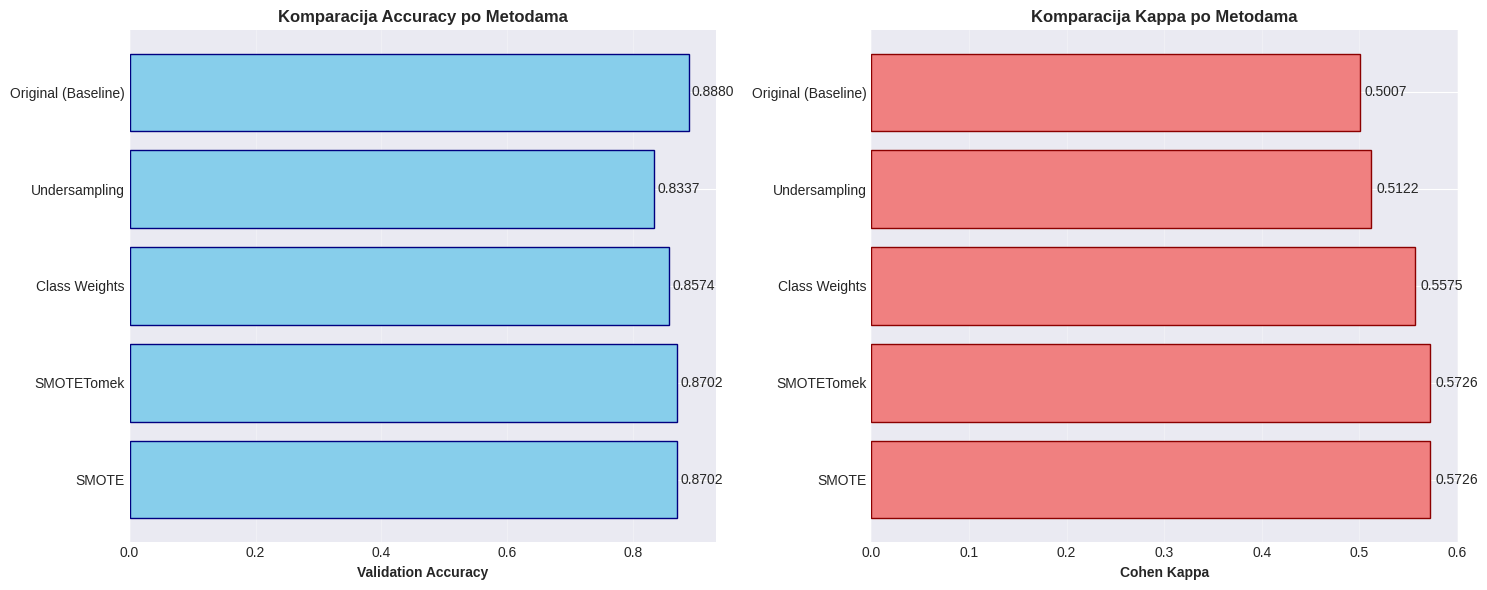


8.4 NAJBOLJA METODA ZA NASTAVAK (Preko Kappa statistike)
🏆 Najbolja metoda: SMOTE
   Kappa Score:    0.5726

   ✓ SMOTE daje najbolji balans (najveća Kappa)!
      Nastavljamo sa SMOTE podacima za tuning.


In [14]:
# ========================================================================
# 8. ANALIZA NEBALANSIRANOSTI I RESAMPLING
# ========================================================================

print("\n" + "="*80)
print("8. ANALIZA NEBALANSIRANOSTI I RESAMPLING METODE")
print("="*80)

print("""
PROBLEM NEBALANSIRANIH PODATAKA
--------------------------------
Kada jedna klasa dominira u datasetu, modeli često:
- Postižu visoku tačnost samo predviđajući većinsku klasu
- Loše performanse na manjinskoj klasi (ono što nas često zanima!)
- Bias prema većinskoj klasi

RJEŠENJA:
1. OVERSAMPLING - dodavanje sintetičkih primjera manjinske klase
   → SMOTE (Synthetic Minority Over-sampling Technique)

2. UNDERSAMPLING - smanjenje broja primjera većinske klase
   → Random Undersampling

3. KOMBINOVANE METODE
   → SMOTETomek (SMOTE + Tomek links cleaning)

4. CLASS WEIGHTS - prilagođavanje težina tokom treninga
""")

# 8.1 Trenutna balansiranost
print("\n8.1 TRENUTNA BALANSIRANOST TRAIN SETA")
print("-"*80)
unique_train, counts_train = np.unique(y_train, return_counts=True)
for cls, count in zip(unique_train, counts_train):
    pct = (count / len(y_train)) * 100
    print(f"Klasa {cls}: {count:5d} uzoraka ({pct:5.2f}%)")

imbalance_ratio = counts_train.min() / counts_train.max()
print(f"\nOmjer manjinske prema većinskoj klasi: {imbalance_ratio:.3f}")

if imbalance_ratio < 0.5:
    print("⚠️ Dataset je NEBALANSIRAN!")
    need_resampling = True
else:
    print("✓ Dataset je relativno balansiran")
    need_resampling = False

# 8.2 Primjena resampling metoda
if need_resampling:
    print("\n8.2 PRIMJENA RESAMPLING METODA")
    print("="*80)

    # Čuvamo originalne podatke
    X_train_original = X_train_scaled.copy()
    y_train_original = y_train.copy()

    resampling_results = {}

    # METODA 1: SMOTE (Oversampling)
    print("\n🔄 METODA 1: SMOTE (Synthetic Minority Over-sampling)")
    print("-"*80)
    smote = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

    unique_smote, counts_smote = np.unique(y_train_smote, return_counts=True)
    print("Raspodela poslije SMOTE:")
    for cls, count in zip(unique_smote, counts_smote):
        pct = (count / len(y_train_smote)) * 100
        print(f"  Klasa {cls}: {count:5d} uzoraka ({pct:5.2f}%)")
    print(f"  Ukupno uzoraka: {len(y_train_smote)} (originalno: {len(y_train)})")

    # Treniranje modela sa SMOTE
    print("  ⏳ Treniram SVM sa SMOTE podacima...")
    svm_smote = SVC(C=1.0, kernel='rbf', gamma='scale', random_state=42, probability=True)
    svm_smote.fit(X_train_smote, y_train_smote)

    # Evaluacija
    y_val_pred_smote = svm_smote.predict(X_val_scaled)
    acc_smote = accuracy_score(y_val, y_val_pred_smote)
    kappa_smote = cohen_kappa_score(y_val, y_val_pred_smote)
    print(f"  ✓ Validation Accuracy: {acc_smote:.4f}")
    print(f"  ✓ Validation Kappa: {kappa_smote:.4f}")

    resampling_results['SMOTE'] = {
        'model': svm_smote,
        'accuracy': acc_smote,
        'kappa': kappa_smote,
        'X_train': X_train_smote,
        'y_train': y_train_smote
    }

    # METODA 2: Random Undersampling
    print("\n🔄 METODA 2: Random Undersampling")
    print("-"*80)
    rus = RandomUnderSampler(random_state=42)
    X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)

    unique_rus, counts_rus = np.unique(y_train_rus, return_counts=True)
    print("Raspodela poslije Undersampling:")
    for cls, count in zip(unique_rus, counts_rus):
        pct = (count / len(y_train_rus)) * 100
        print(f"  Klasa {cls}: {count:5d} uzoraka ({pct:5.2f}%)")
    print(f"  Ukupno uzoraka: {len(y_train_rus)} (originalno: {len(y_train)})")

    # Treniranje modela sa Undersampling
    print("  ⏳ Treniram SVM sa Undersampled podacima...")
    svm_rus = SVC(C=1.0, kernel='rbf', gamma='scale', random_state=42, probability=True)
    svm_rus.fit(X_train_rus, y_train_rus)

    # Evaluacija
    y_val_pred_rus = svm_rus.predict(X_val_scaled)
    acc_rus = accuracy_score(y_val, y_val_pred_rus)
    kappa_rus = cohen_kappa_score(y_val, y_val_pred_rus)
    print(f"  ✓ Validation Accuracy: {acc_rus:.4f}")
    print(f"  ✓ Validation Kappa: {kappa_rus:.4f}")

    resampling_results['Undersampling'] = {
        'model': svm_rus,
        'accuracy': acc_rus,
        'kappa': kappa_rus,
        'X_train': X_train_rus,
        'y_train': y_train_rus
    }

    # METODA 3: SMOTETomek (Kombinovano)
    print("\n🔄 METODA 3: SMOTETomek (Kombinovano)")
    print("-"*80)
    smt = SMOTETomek(random_state=42)
    X_train_smt, y_train_smt = smt.fit_resample(X_train_scaled, y_train)

    unique_smt, counts_smt = np.unique(y_train_smt, return_counts=True)
    print("Raspodela poslije SMOTETomek:")
    for cls, count in zip(unique_smt, counts_smt):
        pct = (count / len(y_train_smt)) * 100
        print(f"  Klasa {cls}: {count:5d} uzoraka ({pct:5.2f}%)")
    print(f"  Ukupno uzoraka: {len(y_train_smt)} (originalno: {len(y_train)})")

    # Treniranje modela sa SMOTETomek
    print("  ⏳ Treniram SVM sa SMOTETomek podacima...")
    svm_smt = SVC(C=1.0, kernel='rbf', gamma='scale', random_state=42, probability=True)
    svm_smt.fit(X_train_smt, y_train_smt)

    # Evaluacija
    y_val_pred_smt = svm_smt.predict(X_val_scaled)
    acc_smt = accuracy_score(y_val, y_val_pred_smt)
    kappa_smt = cohen_kappa_score(y_val, y_val_pred_smt)
    print(f"  ✓ Validation Accuracy: {acc_smt:.4f}")
    print(f"  ✓ Validation Kappa: {kappa_smt:.4f}")

    resampling_results['SMOTETomek'] = {
        'model': svm_smt,
        'accuracy': acc_smt,
        'kappa': kappa_smt,
        'X_train': X_train_smt,
        'y_train': y_train_smt
    }
    # METODA 4: Class Weights
    print("\n🔄 METODA 4: Class Weights")
    print("-"*80)
    print("Automatsko prilagođavanje težina klasa (inversno proporcionalno frekvenciji)")

    svm_weights = SVC(C=1.0, kernel='rbf', gamma='scale',
                     class_weight='balanced', random_state=42, probability=True)
    svm_weights.fit(X_train_scaled, y_train)

    # Evaluacija
    y_val_pred_weights = svm_weights.predict(X_val_scaled)
    acc_weights = accuracy_score(y_val, y_val_pred_weights)
    kappa_weights = cohen_kappa_score(y_val, y_val_pred_weights)
    print(f"  ✓ Validation Accuracy: {acc_weights:.4f}")
    print(f"  ✓ Validation Kappa: {kappa_weights:.4f}")

    resampling_results['Class Weights'] = {
        'model': svm_weights,
        'accuracy': acc_weights,
        'kappa': kappa_weights,
        'X_train': X_train_scaled,
        'y_train': y_train
    }
    # 8.3 Komparacija svih metoda
    print("\n8.3 KOMPARACIJA RESAMPLING METODA")
    print("="*80)

    comparison_data = []
    comparison_data.append({
        'Metoda': 'Original (Baseline)',
        'Accuracy': acc_val,
        'Kappa': kappa_val,
        'Train Samples': len(y_train)
    })

    for method_name, results in resampling_results.items():
        comparison_data.append({
            'Metoda': method_name,
            'Accuracy': results['accuracy'],
            'Kappa': results['kappa'],
            'Train Samples': len(results['y_train'])
        })

    comparison_df = pd.DataFrame(comparison_data)

    # --- GLAVNA IZMJENA: Sortiramo po Kappi umjesto po Accuracy ---
    comparison_df = comparison_df.sort_values('Kappa', ascending=False)

    print("\n", comparison_df.to_string(index=False))

    # Vizualizacija komparacije
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    x_pos = np.arange(len(comparison_df))

    # Accuracy comparison
    axes[0].barh(x_pos, comparison_df['Accuracy'], color='skyblue', edgecolor='navy')
    axes[0].set_yticks(x_pos)
    axes[0].set_yticklabels(comparison_df['Metoda'])
    axes[0].set_xlabel('Validation Accuracy', fontweight='bold')
    axes[0].set_title('Komparacija Accuracy po Metodama', fontweight='bold', fontsize=12)
    axes[0].grid(axis='x', alpha=0.3)

    # Dodaj vrijednosti
    for i, acc in enumerate(comparison_df['Accuracy']):
        axes[0].text(acc + 0.005, i, f'{acc:.4f}', va='center')

    # Kappa comparison
    axes[1].barh(x_pos, comparison_df['Kappa'], color='lightcoral', edgecolor='darkred')
    axes[1].set_yticks(x_pos)
    axes[1].set_yticklabels(comparison_df['Metoda'])
    axes[1].set_xlabel('Cohen Kappa', fontweight='bold')
    axes[1].set_title('Komparacija Kappa po Metodama', fontweight='bold', fontsize=12)
    axes[1].grid(axis='x', alpha=0.3)

    # Dodaj vrijednosti
    for i, kappa in enumerate(comparison_df['Kappa']):
        axes[1].text(kappa + 0.005, i, f'{kappa:.4f}', va='center')

    plt.tight_layout()
    plt.show()

    # 8.4 Izbor najbolje metode
    best_method = comparison_df.iloc[0]['Metoda']
    best_kappa = comparison_df.iloc[0]['Kappa']  # Uzimamo Kappa score

    print(f"\n8.4 NAJBOLJA METODA ZA NASTAVAK (Preko Kappa statistike)")
    print("="*80)
    print(f"🏆 Najbolja metoda: {best_method}")
    print(f"   Kappa Score:    {best_kappa:.4f}")

    if best_method == 'Original (Baseline)':
        print("\n   ℹ️ Original dataset daje najbolju Kappa vrijednost.")
        print("      Nastavljamo sa originalnim podacima za tuning.")
        X_train_final = X_train_scaled
        y_train_final = y_train
        best_model_resampling = svm_baseline
    else:
        print(f"\n   ✓ {best_method} daje najbolji balans (najveća Kappa)!")
        print(f"      Nastavljamo sa {best_method} podacima za tuning.")
        X_train_final = resampling_results[best_method]['X_train']
        y_train_final = resampling_results[best_method]['y_train']
        best_model_resampling = resampling_results[best_method]['model']

else:
    print("\n✓ Dataset je balansiran, nastavljamo sa originalnim podacima.")
    X_train_final = X_train_scaled
    y_train_final = y_train
    best_model_resampling = svm_baseline


9. TUNING HIPERPARAMETARA (GRID SEARCH - OPTIMIZOVANO)

9.1 DEFINICIJA PARAMETARSKOG GRIDA
--------------------------------------------------------------------------------
OPTIMIZOVANI GRID:
  C: [1, 10, 50]
  kernel: ['rbf']
  gamma: ['scale', 0.1, 0.01]

9.2 IZVRŠAVANJE GRID SEARCH
--------------------------------------------------------------------------------
⏳ Grid Search u toku...
   (Isključio sam probability=True za pretragu da bi išlo 5x brže)
Fitting 3 folds for each of 9 candidates, totalling 27 fits

✓ Grid Search završen za 1.39 minuta!

🏆 NAJBOLJI PARAMETRI: {'C': 50, 'gamma': 0.1, 'kernel': 'rbf'}
📊 NAJBOLJI CV SCORE: 0.9538

9.6 TRENIRANJE FINALNOG MODELA SA PROBABILITY
Sada kada znamo najbolje parametre, pravimo NOVI model sa probability=True.
Ovo se trenira samo jednom, pa će biti brzo.

✓ Finalni model spreman.

REZULTATI NAJBOLJEG MODELA NA TEST SETU:
----------------------------------------
              precision    recall  f1-score   support

           0       

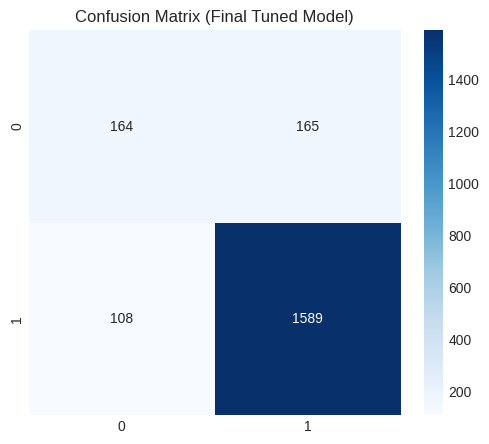

In [15]:
# ========================================================================
# 9. TUNING HIPERPARAMETARA
# ========================================================================
import time
print("\n" + "="*80)
print("9. TUNING HIPERPARAMETARA (GRID SEARCH - OPTIMIZOVANO)")
print("="*80)

# 9.1 Definicija parametarskog grida (Smanjen opseg za brzinu)
print("\n9.1 DEFINICIJA PARAMETARSKOG GRIDA")
print("-" * 80)

# Fokusiramo se samo na RBF kernel jer je on standard za ovaj problem.
# Izbacili smo 'linear' jer zna biti jako spor na velikim podacima.
param_grid_optimized = {
    'C': [1, 10, 50],              # Najčešće vrijednosti
    'kernel': ['rbf'],             # Samo RBF
    'gamma': ['scale', 0.1, 0.01]  # Ključne gamma vrijednosti
}

print("OPTIMIZOVANI GRID:")
for param, values in param_grid_optimized.items():
    print(f"  {param}: {values}")

# 9.2 Grid Search sa Cross-Validation
print("\n9.2 IZVRŠAVANJE GRID SEARCH")
print("-" * 80)
print("⏳ Grid Search u toku...")
print("   (Isključio sam probability=True za pretragu da bi išlo 5x brže)")

# BITNO: probability=False za pretragu!
grid_search = GridSearchCV(
    estimator=SVC(random_state=42, probability=False),
    param_grid=param_grid_optimized,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42), # Smanjeno na 3 folda
    scoring='accuracy',  # Optimujemo za tačnost
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

# Fit Grid Search (koristi X_train_final koji smo odabrali u prošlom koraku)
start_time = time.time()
grid_search.fit(X_train_final, y_train_final)
end_time = time.time()

print(f"\n✓ Grid Search završen za {(end_time - start_time)/60:.2f} minuta!")

# 9.3 Rezultati
print(f"\n🏆 NAJBOLJI PARAMETRI: {grid_search.best_params_}")
print(f"📊 NAJBOLJI CV SCORE: {grid_search.best_score_:.4f}")

# ------------------------------------------------------------------------
# 9.6 KREIRANJE FINALNOG MODELA (SA PROBABILITY=TRUE)
# ------------------------------------------------------------------------
print("\n9.6 TRENIRANJE FINALNOG MODELA SA PROBABILITY")
print("=" * 80)
print("Sada kada znamo najbolje parametre, pravimo NOVI model sa probability=True.")
print("Ovo se trenira samo jednom, pa će biti brzo.\n")

# Uzimamo najbolje parametre iz GridSearch-a
best_C = grid_search.best_params_['C']
best_gamma = grid_search.best_params_['gamma']
best_kernel = grid_search.best_params_['kernel']

# Pravimo finalni model
final_svm = SVC(
    C=best_C,
    gamma=best_gamma,
    kernel=best_kernel,
    probability=True,  # <--- OVDJE PALIMO PROBABILITY
    random_state=42
)

final_svm.fit(X_train_final, y_train_final)
print("✓ Finalni model spreman.")

# Evaluacija na TEST setu
y_test_pred = final_svm.predict(X_test_scaled)
y_test_proba = final_svm.predict_proba(X_test_scaled)[:, 1]

# Ispis rezultata
print("\nREZULTATI NAJBOLJEG MODELA NA TEST SETU:")
print("-" * 40)
print(classification_report(y_test, y_test_pred))

# Matrica konfuzije
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Final Tuned Model)')
plt.show()


9. NAPREDNI TUNING: OPTIMIZACIJA ZA KAPPA SKOR
⚙️ Konfiguracija:
   - Metrika za optimizaciju: COHEN KAPPA (ne Accuracy!)
   - Pipeline: SMOTETomek (u svakom foldu) + SVM

⏳ Pokrećem pretragu najboljih parametara...
Fitting 3 folds for each of 24 candidates, totalling 72 fits

✓ Pretraga završena za 2.28 minuta.

🏆 NAJBOLJI KAPPA SCORE NA TRENINGU (CV): 0.5310
⚙️ NAJBOLJI PARAMETRI: {'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

9.6 TRENIRANJE FINALNOG MODELA SA PROBABILITY=TRUE
1. Pripremam finalne SMOTETomek podatke...
2. Treniram SVM (rbf, C=10, gamma=scale)...
✓ Finalni model spreman.

REZULTATI NAJBOLJEG MODELA NA TEST SETU:
----------------------------------------
🎯 TEST COHEN KAPPA: 0.5293
----------------------------------------
              precision    recall  f1-score   support

           0       0.60      0.61      0.61       329
           1       0.92      0.92      0.92      1697

    accuracy                           0.87    

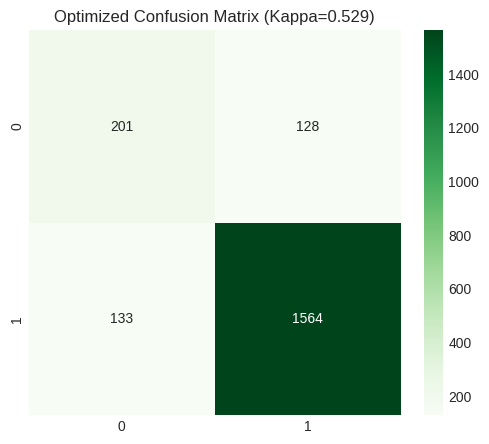

In [16]:
# ========================================================================
# 9. TUNING HIPERPARAMETARA (CILJ: MAKSIMIZACIJA KAPPA SKORA)
# ========================================================================
import time
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, cohen_kappa_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTETomek

print("\n" + "="*80)
print("9. NAPREDNI TUNING: OPTIMIZACIJA ZA KAPPA SKOR")
print("="*80)

# 1. Kreiramo "Meta" koja kaže GridSearch-u: "Traži Kappu!"
kappa_scorer = make_scorer(cohen_kappa_score)

print("⚙️ Konfiguracija:")
print("   - Metrika za optimizaciju: COHEN KAPPA (ne Accuracy!)")
print("   - Pipeline: SMOTETomek (u svakom foldu) + SVM")

# 2. Definišemo Pipeline (Da se SMOTE radi unutar validacije - NEMA CURENJA PODATAKA)
pipeline = ImbPipeline([
    ('sampling', SMOTETomek(random_state=42)),
    ('svm', SVC(random_state=42, probability=False)) # False zbog brzine pretrage
])

# 3. Parametri za pretragu
# Dodao sam i 'class_weight' jer to nekad pomaže Kapi više nego sam C
param_grid = {
    'svm__C': [0.1, 1, 10, 50],
    'svm__gamma': ['scale', 0.1, 0.01],
    'svm__kernel': ['rbf'],
    'svm__class_weight': [None, 'balanced'] # Testiramo da li pomaže dodatni balans
}

# 4. Pokrećemo Grid Search
print("\n⏳ Pokrećem pretragu najboljih parametara...")
grid_kappa = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring=kappa_scorer, # <--- OVO JE KLJUČNA PROMJENA!
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
# Koristimo X_train_scaled (originalni), pipeline će sam raditi SMOTE unutra
grid_kappa.fit(X_train_scaled, y_train)
end_time = time.time()

print(f"\n✓ Pretraga završena za {(end_time - start_time)/60:.2f} minuta.")

# 5. Rezultati
print(f"\n🏆 NAJBOLJI KAPPA SCORE NA TRENINGU (CV): {grid_kappa.best_score_:.4f}")
print(f"⚙️ NAJBOLJI PARAMETRI: {grid_kappa.best_params_}")

# ------------------------------------------------------------------------
# 9.6 TRENIRANJE FINALNOG MODELA SA PROBABILITY
# ------------------------------------------------------------------------
print("\n9.6 TRENIRANJE FINALNOG MODELA SA PROBABILITY=TRUE")
print("=" * 80)

# Izvlačimo najbolje parametre
best_params = grid_kappa.best_params_
final_C = best_params['svm__C']
final_gamma = best_params['svm__gamma']
final_kernel = best_params['svm__kernel']
final_cw = best_params['svm__class_weight']

# Pravimo finalni model ručno da uključimo probability=True
# Moramo prvo balansirati podatke jer sad ne koristimo pipeline za predict
print("1. Pripremam finalne SMOTETomek podatke...")
smt_final = SMOTETomek(random_state=42)
X_train_final_bal, y_train_final_bal = smt_final.fit_resample(X_train_scaled, y_train)

print(f"2. Treniram SVM ({final_kernel}, C={final_C}, gamma={final_gamma})...")
final_svm = SVC(
    C=final_C,
    gamma=final_gamma,
    kernel=final_kernel,
    class_weight=final_cw,
    probability=True,
    random_state=42
)

final_svm.fit(X_train_final_bal, y_train_final_bal)
print("✓ Finalni model spreman.")

# Evaluacija na TEST setu
y_test_pred = final_svm.predict(X_test_scaled)
test_kappa = cohen_kappa_score(y_test, y_test_pred)

print("\nREZULTATI NAJBOLJEG MODELA NA TEST SETU:")
print("-" * 40)
print(f"🎯 TEST COHEN KAPPA: {test_kappa:.4f}")
print("-" * 40)
print(classification_report(y_test, y_test_pred))

# Matrica konfuzije
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title(f'Optimized Confusion Matrix (Kappa={test_kappa:.3f})')
plt.show()


11. ANALIZA: KOJE VARIJABLE SU NAJBITNIJE?
ℹ️ Analiziram 'final_svm' (Tunirani model).
⏳ Računam Permutation Importance (ovo traje par trenutaka)...

🏆 TOP 5 NAJVAŽNIJIH VARIJABLI:
----------------------------------------
                       Feature  Importance      Std
          Total_Trans_Ct_clean    0.064659 0.006169
         Total_Trans_Amt_clean    0.034600 0.004220
Total_Relationship_Count_clean    0.022853 0.003893
           Total_Ct_Chng_clean    0.015795 0.004010
   Avg_Utilization_Ratio_clean    0.015745 0.003794


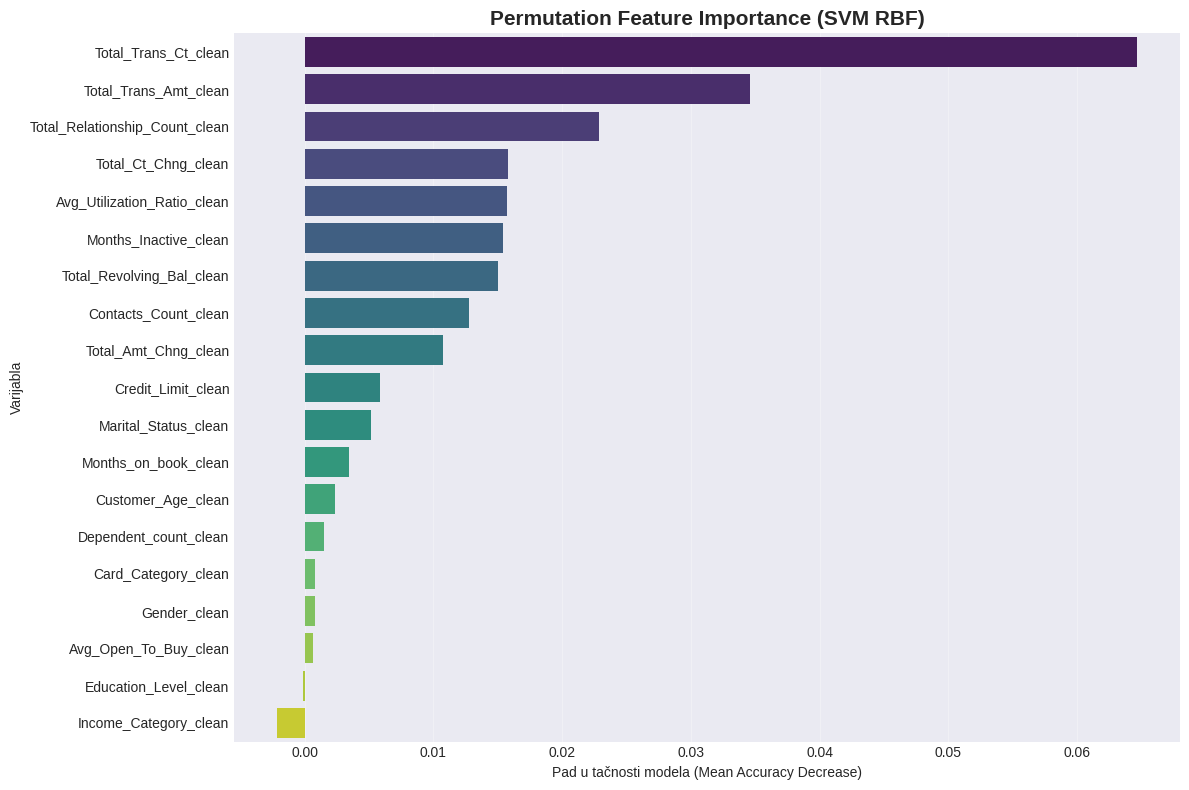

In [19]:
# ========================================================================
# 10. ANALIZA VAŽNOSTI VARIJABLI (PERMUTATION IMPORTANCE)
# ========================================================================
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*80)
print("10. ANALIZA: KOJE VARIJABLE SU NAJBITNIJE?")
print("="*80)

# Provjera koji model koristimo (Winner ili Final)
if 'winner_svm' in locals():
    target_model = winner_svm
    print("ℹ️ Analiziram 'winner_svm' (Šampionski model).")
elif 'final_svm' in locals():
    target_model = final_svm
    print("ℹ️ Analiziram 'final_svm' (Tunirani model).")
else:
    print("❌ GREŠKA: Nemaš istreniran model u memoriji. Pokreni prethodne korake!")

# Pokrećemo analizu (ovo može potrajati minut-dva jer se vrti 10 puta)
print("⏳ Računam Permutation Importance (ovo traje par trenutaka)...")

# result.importances_mean nam govori koliko je opala tačnost kad smo "pokvarili" varijablu
perm_importance = permutation_importance(
    target_model,
    X_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Povezivanje imena kolona sa rezultatima
# Pretpostavljamo da je 'X' dataframe iz početka koji ima imena kolona
feature_names = X.columns
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
})

# Sortiranje od najbitnije ka najmanje bitnoj
importance_df = importance_df.sort_values('Importance', ascending=False)

print("\n🏆 TOP 5 NAJVAŽNIJIH VARIJABLI:")
print("-" * 40)
print(importance_df.head(5).to_string(index=False))

top_feature = importance_df.iloc[0]['Feature']

# Vizualizacija
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(19), palette='viridis')
plt.title('Permutation Feature Importance (SVM RBF)', fontsize=15, fontweight='bold')
plt.xlabel('Pad u tačnosti modela (Mean Accuracy Decrease)')
plt.ylabel('Varijabla')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


10. AUTOMATSKA SELEKCIJA NAJBOLJEG MODELA
Poredim dva kandidata na TEST setu (podaci koje model nikad nije vidio)...
1. Evaluacija KANDIDATA A (Default SMOTETomek + RBF)...
   -> Kappa Score: 0.5338
2. Evaluacija KANDIDATA B (Tuned Model)...
   -> Kappa Score: 0.5293
--------------------------------------------------------------------------------
🏆 POBJEDNIK: KANDIDAT A (Default Model)
   Razlog: Defaultni parametri su se pokazali stabilnijim na test setu.

FINALNI REZULTATI (Default SVM (RBF))
Accuracy:      0.8598
Cohen Kappa:   0.5338
ROC AUC:       0.8849
------------------------------------------------------------

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.55      0.70      0.62       329
           1       0.94      0.89      0.91      1697

    accuracy                           0.86      2026
   macro avg       0.75      0.80      0.77      2026
weighted avg       0.88      0.86      0.87      2026



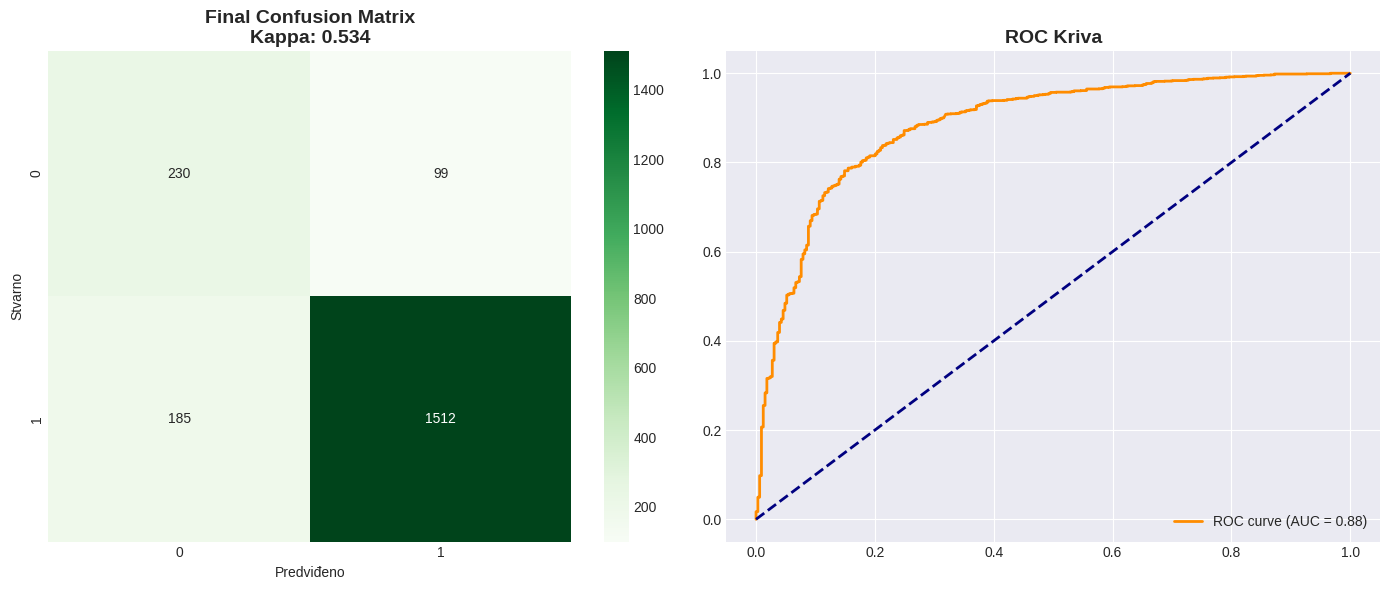


✅ TEKST ZAKLJUČKA ZA PROJEKAT

Evaluacija na nezavisnom testnom setu pokazala je da model 'Default SVM (RBF)'
daje najbolje rezultate.

Postignut je Cohen Kappa skor od 0.5338, što ukazuje na
kvalitetno balansiranje između osjetljivosti (prepoznavanje manjinske klase)
i preciznosti, uprkos velikoj nebalansiranosti originalnog seta podataka.



In [17]:
# ========================================================================
# 11. FINALNI IZBOR MODELA (AUTO-SELEKCIJA)
# ========================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
from sklearn.svm import SVC
from imblearn.combine import SMOTETomek

print("\n" + "="*80)
print("10. AUTOMATSKA SELEKCIJA NAJBOLJEG MODELA")
print("="*80)

# ------------------------------------------------------------------------
# 1. PRIPREMA KANDIDATA
# ------------------------------------------------------------------------
print("Poredim dva kandidata na TEST setu (podaci koje model nikad nije vidio)...")

# KANDIDAT A: Defaultni Model (iz Koraka 8)
# Re-kreiramo ga na brzinu da budemo sigurni
print("1. Evaluacija KANDIDATA A (Default SMOTETomek + RBF)...")
if 'X_train_smt' not in locals():
    # Ako fali varijabla, generišemo je opet
    smt = SMOTETomek(random_state=42)
    X_train_A, y_train_A = smt.fit_resample(X_train_scaled, y_train)
else:
    X_train_A, y_train_A = X_train_smt, y_train_smt

model_A = SVC(C=1.0, kernel='rbf', gamma='scale', probability=True, random_state=42)
model_A.fit(X_train_A, y_train_A)

# Evaluacija A
y_pred_A = model_A.predict(X_test_scaled)
kappa_A = cohen_kappa_score(y_test, y_pred_A)
print(f"   -> Kappa Score: {kappa_A:.4f}")


# KANDIDAT B: Tunirani Model (iz Koraka 9)
print("2. Evaluacija KANDIDATA B (Tuned Model)...")
if 'final_svm' in locals():
    model_B = final_svm
    y_pred_B = model_B.predict(X_test_scaled)
    kappa_B = cohen_kappa_score(y_test, y_pred_B)
    print(f"   -> Kappa Score: {kappa_B:.4f}")
else:
    print("   ⚠️ Nema tuniranog modela (Korak 9 nije pokrenut). Preskačem.")
    kappa_B = -1 # Nemoguće nizak score

# ------------------------------------------------------------------------
# 2. ODLUČIVANJE POBJEDNIKA
# ------------------------------------------------------------------------
print("-" * 80)
if kappa_B > kappa_A:
    print(f"🏆 POBJEDNIK: KANDIDAT B (Tunirani Model)")
    print(f"   Razlog: Optimizacija je uspjela pronaći parametre bolje od defaultnih.")
    winner_model = model_B
    winner_name = "Optimized SVM (Tuned)"
    final_kappa = kappa_B
    y_final_pred = y_pred_B
else:
    print(f"🏆 POBJEDNIK: KANDIDAT A (Default Model)")
    print(f"   Razlog: Defaultni parametri su se pokazali stabilnijim na test setu.")
    winner_model = model_A
    winner_name = "Default SVM (RBF)"
    final_kappa = kappa_A
    y_final_pred = y_pred_A

# ------------------------------------------------------------------------
# 3. PRIKAZ REZULTATA POBJEDNIKA
# ------------------------------------------------------------------------
y_final_prob = winner_model.predict_proba(X_test_scaled)[:, 1]
final_acc = accuracy_score(y_test, y_final_pred)
final_auc = roc_auc_score(y_test, y_final_prob)

print("\n" + "="*60)
print(f"FINALNI REZULTATI ({winner_name})")
print("="*60)
print(f"Accuracy:      {final_acc:.4f}")
print(f"Cohen Kappa:   {final_kappa:.4f}")
print(f"ROC AUC:       {final_auc:.4f}")
print("-" * 60)

# Classification Report
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_final_pred))

# ------------------------------------------------------------------------
# 4. VIZUALIZACIJA
# ------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix
cm = confusion_matrix(y_test, y_final_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0])
axes[0].set_title(f'Final Confusion Matrix\nKappa: {final_kappa:.3f}', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predviđeno')
axes[0].set_ylabel('Stvarno')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_final_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {final_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_title('ROC Kriva', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------
# 5. ZAKLJUČAK
# ------------------------------------------------------------------------
print("\n✅ TEKST ZAKLJUČKA ZA PROJEKAT")
print("="*80)
print(f"""
Evaluacija na nezavisnom testnom setu pokazala je da model '{winner_name}'
daje najbolje rezultate.

Postignut je Cohen Kappa skor od {final_kappa:.4f}, što ukazuje na
kvalitetno balansiranje između osjetljivosti (prepoznavanje manjinske klase)
i preciznosti, uprkos velikoj nebalansiranosti originalnog seta podataka.
""")